# Comparing overturning circulation in ACCESS-OM3 with ACCESS-OM2

See https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/7

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json"
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# What physical field you want, in CF terms (stays the same across models)
variable_standard_name = "Ocean Mass Y Transport"

# Fallback variable name to use if the catalog doesn’t expose standard_name
fallback_variable_names = ["vmo"]

# Frequency depends on the datastore you’re using:
data_frequency = "1mon"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/"
nbname = "Overturning_in_ACCESS_OM3.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
import os
from exptdata_access import guess_experiment_from_esm_file, get_exptname_from_path
from model_agnostic import get_lon_lat_from_catalog, select_variable, patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

# Infer model information from the datastore path
expt_key, info = guess_experiment_from_esm_file(esm_file)

model_name = info["model"]             # OM3 or CM3
exptname = get_exptname_from_path(esm_file)
print(f"Running notebook for model: {model_name}")
print("ESM datastore path:", esm_file)
print("Experiment name:", exptname)

Running notebook for model: ACCESS-OM3
ESM datastore path: /g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json
Experiment name: MC_8km_jra_ryf-test2-expt-c349f800


In [5]:
import intake
from dask.distributed import Client
import matplotlib.pyplot as plt
import cmocean as cm
import cftime
import cartopy.crs as ccrs
import os
import cartopy.feature as cft
from textwrap import wrap
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
import glob
import re
from pint import application_registry as ureg
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [6]:
IAF = esm_file.find('iaf') > 0
IAF

False

In [7]:
def load_cm2(pattern, varname, rename_dims=None, drop_vars=(), time_slice=None):
    files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No files matched: {pattern}")

    def _ym_from_filename(fname):
        base = os.path.basename(fname)
        m = re.search(r"ym_(\d+)_(\d+)\.nc$", base)
        if not m:
            raise ValueError(f"Could not parse year/month from filename: {base}")
        return int(m.group(1)), int(m.group(2))

    def _to_ym_key(dt):
        if hasattr(dt, "year") and hasattr(dt, "month"):
            return int(dt.year) * 12 + int(dt.month)
        raise TypeError(f"Unsupported time value for mapping: {dt!r}")

    if time_slice is not None and getattr(time_slice, "start", None) is not None and getattr(time_slice, "stop", None) is not None:
        start_key = _to_ym_key(time_slice.start)
        stop_key = _to_ym_key(time_slice.stop)
        if stop_key < start_key:
            start_key, stop_key = stop_key, start_key

        ym_keys = []
        for f in files:
            y, m = _ym_from_filename(f)
            ym_keys.append(y * 12 + m)

        diffs = [b - a for a, b in zip(ym_keys[:-1], ym_keys[1:]) if b > a]
        file_span_months = max(1, min(diffs) if diffs else 1)

        def _select_files(shift_months=0):
            return [
                f
                for f, key in zip(files, ym_keys)
                if (key + shift_months) <= stop_key
                and (key + shift_months + file_span_months - 1) >= start_key
            ]

        subset = _select_files(0)
        shift_used = 0

        if not subset:
            file_min = min(ym_keys)
            file_max = max(ym_keys) + file_span_months - 1
            for shift in (stop_key - file_max, start_key - file_min):
                if shift == 0:
                    continue
                candidate = _select_files(shift)
                if candidate:
                    subset = candidate
                    shift_used = shift
                    break

        if not subset:
            raise RuntimeError(
                f"load_cm2[{varname}]: could not map timerange to filenames; refusing to open all {len(files)} files"
            )

        print(f"load_cm2[{varname}]: using {len(subset)}/{len(files)} files")
        if shift_used:
            print(f"load_cm2[{varname}]: shifted window by {shift_used} months")
        files = subset

    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    open_kwargs = dict(
        combine="nested",
        concat_dim="time",
        parallel=False,
        engine="netcdf4",
        chunks={"time": 12},
        drop_variables=drop_vars,
        decode_times=time_coder,
        decode_timedelta=True,
        decode_coords=False,
        data_vars="minimal",
        coords="minimal",
        compat="override",
        join="override",
        create_default_indexes=False,
    )

    try:
        ds = xr.open_mfdataset(files, **open_kwargs)
    except TypeError:
        open_kwargs.pop("create_default_indexes", None)
        ds = xr.open_mfdataset(files, **open_kwargs)

    da = ds[varname]

    if "time" in da.dims:
        da = da.sortby("time")

    if rename_dims:
        present = {k: v for k, v in rename_dims.items() if k in da.dims}
        da = da.rename(present)

    return da

## Load ACCESS-OM3 data from ESM datastore

In [8]:
datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

In [9]:
try:
    from distributed import get_client
    get_client().close()
except ValueError:
    pass
if "client" in globals():
    del client

if model_name == "ACCESS-OM3":
    da_model = select_variable(
        datastore,
        variable_standard_name=variable_standard_name,
        fallback_variable_names=fallback_variable_names,
        data_frequency=data_frequency,
        chunks={"time": -1, "rho2_l": "auto", "yq": "auto", "xh": "auto"},  # chunk space too, or 8km chunks are >10GB
    )
elif model_name == "ACCESS-CM3":
    da_model = select_variable(
        datastore,
        variable_standard_name=variable_standard_name,
        fallback_variable_names=fallback_variable_names,
        data_frequency=data_frequency,
        chunks={"time": 1},
    )
print("Selected variable:", da_model.name)
print("dims:", da_model.dims)

CF-based lookup failed: ValueError('No entries found for this CF standard_name.')


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a145257e30>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a145219100>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:66: UserWarning: An error occurred while loading the GDAC data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a144bfd1c0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:91: UserWarning: An error occurred while loading the ERDDAP index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a144df4770>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a145225130>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a144bfd0d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x14a1437d10d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


Selected variable via fallback name: vmo
Selected variable: vmo
dims: ('time', 'rho2_l', 'yq', 'xh')


In [10]:
# Discover lon/lat from the catalog (using the helper we wrote earlier)
lon, lat = get_lon_lat_from_catalog(datastore)

# Ensure model_all has CF longitude/latitude coords
try:
    # If CF coords already exist, just use them
    _ = da_model.cf["longitude"]
    _ = da_model.cf["latitude"]
    model_all = da_model
    print("Using existing CF longitude/latitude on da_model.")
except KeyError:
    # Otherwise, attach the lon/lat we discovered
    model_all = da_model.cf.assign_coords(
        {
            "longitude": lon,
            "latitude": lat,
        }
    )
    print("Attached longitude/latitude from catalog grid variables.")

print("model_all dims:", model_all.dims)

Using existing CF longitude/latitude on da_model.
model_all dims: ('time', 'rho2_l', 'yq', 'xh')


In [11]:
vmo_all = model_all.sel(yq=slice(None, 65)) # omit tripolar region https://github.com/COSIMA/cosima-recipes/issues/510

In [12]:
if exptname == "25km-iaf-test-for-AK-expt-7df5ef4c":
# omit latitudes with grid bug https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
    vmo_all = vmo_all.isel(yq=slice(10, None))

### Load and plot data from ACCESS-OM2
use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7

In [13]:
if model_name == 'ACCESS-OM3':
    if IAF:
        om2exptname = '025deg_jra55_iaf_omip2_cycle1'
        frequency = '1mon'
    else:
        om2exptname = '025deg_jra55_ryf9091_gadi' # Note that this simulation doesn't have the GM component of the overturning as a diagnostic - it has GM switched on, but not diagnosed.
        frequency='1yr' # for 025deg_jra55_ryf9091_gadi

    datastore = intake.cat.access_nri[om2exptname]

elif model_name == 'ACCESS-CM3':
    om2exptname = 'cj877'


In [14]:
if model_name == "ACCESS-OM3":
    data_name = 'ACCESS-OM2'
    ty_trans_rho_all = datastore.search(
                                variable='ty_trans_rho',
                                frequency=frequency
                            ).to_dask(
                                        xarray_open_kwargs=dict(
                                        chunks={"time": -1},
                                        decode_timedelta=True,
                                        use_cftime=True)
                                    ).sel(grid_yu_ocean=slice(None, 65))# omit tripolar region https://github.com/COSIMA/cosima-recipes/issues/510

    # same calendar as OM3 (converted below) so they can share time axes
    ty_trans_rho_all = ty_trans_rho_all.convert_calendar("proleptic_gregorian", use_cftime=True)

    try:
        ty_trans_rho_gm_all = datastore.search(
                                variable='ty_trans_rho_gm',
                                frequency=frequency
                            ).to_dask(
                                        xarray_open_kwargs=dict(
                                        chunks={"time": -1},
                                        decode_timedelta=True,
                                        use_cftime=True)
                                    ).sel(grid_yu_ocean=slice(None, 65))# omit tripolar region https://github.com/COSIMA/cosima-recipes/issues/510
        ty_trans_rho_gm_all = ty_trans_rho_gm_all.convert_calendar("proleptic_gregorian", use_cftime=True)
    except Exception:
        print('Warning: ty_trans_rho_gm not found!')
        ty_trans_rho_gm_all = False

elif model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    ty_trans_rho_all = load_cm2(
        "/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-3d-ty_trans_rho-1-monthly-mean-ym_*.nc",
        "ty_trans_rho",
    )

    try:
        ty_trans_rho_gm_all = load_cm2(
            "/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn/ocean-3d-ty_trans_rho_gm-1-monthly-mean-ym_*.nc",
            "ty_trans_rho_gm",        )
    except Exception:
        print('Warning: ty_trans_rho_gm not found!')
        ty_trans_rho_gm_all = False


## Calculate overturning streamfunctions for OM3 and OM2

In [15]:
rho0 = 1035  # reference density for both OM2 and OM3

In [16]:
psi_OM3_all = (
    vmo_all
    .sum("xh")
    .cumsum("rho2_l")
    / rho0
    / 1e6
)

In [17]:
ty_trans_rho_da = ty_trans_rho_all["ty_trans_rho"] if isinstance(ty_trans_rho_all, xr.Dataset) else ty_trans_rho_all
psi_OM2_all  = ty_trans_rho_da.sum("grid_xt_ocean").cumsum("potrho") # NB: cumsum needed here
psi_OM2_all -= ty_trans_rho_da.sum("grid_xt_ocean").sum("potrho")

if ty_trans_rho_gm_all is not False:
    ty_trans_rho_gm_da = ty_trans_rho_gm_all["ty_trans_rho_gm"] if isinstance(ty_trans_rho_gm_all, xr.Dataset) else ty_trans_rho_gm_all
    psi_OM2_all += ty_trans_rho_gm_da.sum("grid_xt_ocean") # NB: cumsum not needed here

psi_OM2_all = psi_OM2_all / rho0 / 1e6


### ... and streamfunctions for North Atlantic only

In [18]:
# NA = slice(-103,-5)  # North Atlantic longitude range at 26°N, including Gulf of Mexico as used in Kiss et al. 2020 Fig 8a
NA = slice(-81.5, 10)  # North Atlantic longitude range at 26°N from Florida to Africa for comparison with RAPID, also extended to 10°E for 55°N transect

In [19]:
psi_OM3_NA = (
    vmo_all
    .sel(xh=NA)
    .sum("xh")
    .cumsum("rho2_l")
    / rho0
    / 1e6
)

In [20]:
ty_trans_rho_da_NA = ty_trans_rho_da.sel(grid_xt_ocean=NA)
psi_OM2_NA  = ty_trans_rho_da_NA.sum("grid_xt_ocean").cumsum("potrho") # NB: cumsum needed here
psi_OM2_NA -= ty_trans_rho_da_NA.sum("grid_xt_ocean").sum("potrho")

if ty_trans_rho_gm_all is not False:
    ty_trans_rho_gm_da_NA = ty_trans_rho_gm_da.sel(grid_xt_ocean=NA)
    psi_OM2_NA += ty_trans_rho_gm_da_NA.sum("grid_xt_ocean") # NB: cumsum not needed here

psi_OM2_NA = psi_OM2_NA / rho0 / 1e6


## Calculate and plot the time-mean overturning streamfunction

In [21]:
# Averaging window: last NYEARS complete years, or an explicit [first, last] period
averaging_period = None   # e.g. [1908, 1909]; None = automatic
NYEARS = 2
from model_agnostic import years_window, year_slice

In [22]:
# 1. Model: explicit period if given, else the last NYEARS complete years
#    (chosen on the native calendar, before any conversion)
om3_window = years_window(model_all.time, NYEARS, period=averaging_period)
timerange = year_slice(om3_window)
print("ACCESS-OM3 averaging window:", om3_window)

# Put model time axis on a common calendar (shared with the OM2 timeseries below)
cal = model_all.time.encoding.get("calendar", None)

if cal not in ("proleptic_gregorian", "gregorian"):
    print(f"Converting calendar from {cal} to proleptic_gregorian")
    model_all = model_all.convert_calendar("proleptic_gregorian", use_cftime=True)
    psi_OM3_all = psi_OM3_all.convert_calendar("proleptic_gregorian", use_cftime=True)
    psi_OM3_NA = psi_OM3_NA.convert_calendar("proleptic_gregorian", use_cftime=True)
else:
    print(f"Calendar already {cal}, no conversion needed")

print("Full model time range:", model_all.time.values[0], "→", model_all.time.values[-1])

psi_OM3 = psi_OM3_all.sel(time=timerange)
print("Windowed dims:", psi_OM3.dims)

ACCESS-OM3 averaging window: (1908, 1909)
Converting calendar from noleap to proleptic_gregorian


Full model time range: 1900-01-16 12:00:00 → 1909-12-16 12:00:00
Windowed dims: ('time', 'rho2_l', 'yq')


In [23]:
%%time
OM3timestr = f"{psi_OM3.time.values[0].strftime('%Y-%m-%d')} - {psi_OM3.time.values[-1].strftime('%Y-%m-%d')}"
psi_OM3 = psi_OM3.mean("time")
psi_OM3.load();

CPU times: user 7min 18s, sys: 58.1 s, total: 8min 16s
Wall time: 10min 38s


In [24]:
# Align OM2 diagnostic time labels to OM3 calendar just before plotting workflow.
if model_name == "ACCESS-CM3":
    if "time" in psi_OM2_all.dims and "time" in psi_OM3_all.dims:
        n_om2 = psi_OM2_all.sizes["time"]
        n_om3 = psi_OM3_all.sizes["time"]
        n_shared = min(n_om2, n_om3)
    
        if n_om2 != n_om3:
            print(f"Aligning OM2/OM3 with last {n_shared} time steps (OM2={n_om2}, OM3={n_om3})")
    
        om3_time_shared = psi_OM3_all.time.isel(time=slice(-n_shared, None))
        psi_OM2_all = (
            psi_OM2_all
            .isel(time=slice(-n_shared, None))
            .assign_coords(time=("time", om3_time_shared.values))
            .sortby("time")
        )
        # keep the North Atlantic streamfunction on the same relabelled time axis
        psi_OM2_NA = (
            psi_OM2_NA
            .isel(time=slice(-n_shared, None))
            .assign_coords(time=("time", om3_time_shared.values))
            .sortby("time")
        )
    else:
        print("Skipping OM2/OM3 time alignment: missing 'time' dimension")

In [25]:
%%time
if model_name == "ACCESS-OM3" and not IAF:
    # RYF: the OM2 RYF control runs to year 2550; keep its timeseries to the end of the OM3 run
    _end = f"{int(psi_OM3_all.time.dt.year[-1]):04d}"
    psi_OM2_all = psi_OM2_all.sel(time=slice(None, _end))
    psi_OM2_NA = psi_OM2_NA.sel(time=slice(None, _end))

# 2. Reference run: the same model years where it has them
try:
    om2_window = years_window(psi_OM2_all.time, NYEARS, within=om3_window, fallback="raise")
except ValueError:
    # no overlap (e.g. OM3 IAF ends in 2023, OM2 IAF cycle 1 in 2018): use the reference's
    # last NYEARS complete years, the closest to the OM3 window
    om2_window = years_window(psi_OM2_all.time, NYEARS)
    print(f"No complete {data_name} year inside {om3_window}: using its last complete years instead")
print(f"{data_name} averaging window:", om2_window)

psi_OM2 = psi_OM2_all.sel(time=year_slice(om2_window))
OM2timestr = f"{psi_OM2.time.values[0].strftime('%Y-%m-%d')} - {psi_OM2.time.values[-1].strftime('%Y-%m-%d')}"
psi_OM2 = psi_OM2.mean("time")
psi_OM2.load();

ACCESS-OM2 averaging window: (1908, 1909)


CPU times: user 5.68 s, sys: 334 ms, total: 6.01 s
Wall time: 6.94 s


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/Overturning_in_ACCESS_OM3_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/Overturning_in_ACCESS_OM3.md
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/Overturning_in_ACCESS_OM3.md successfully.


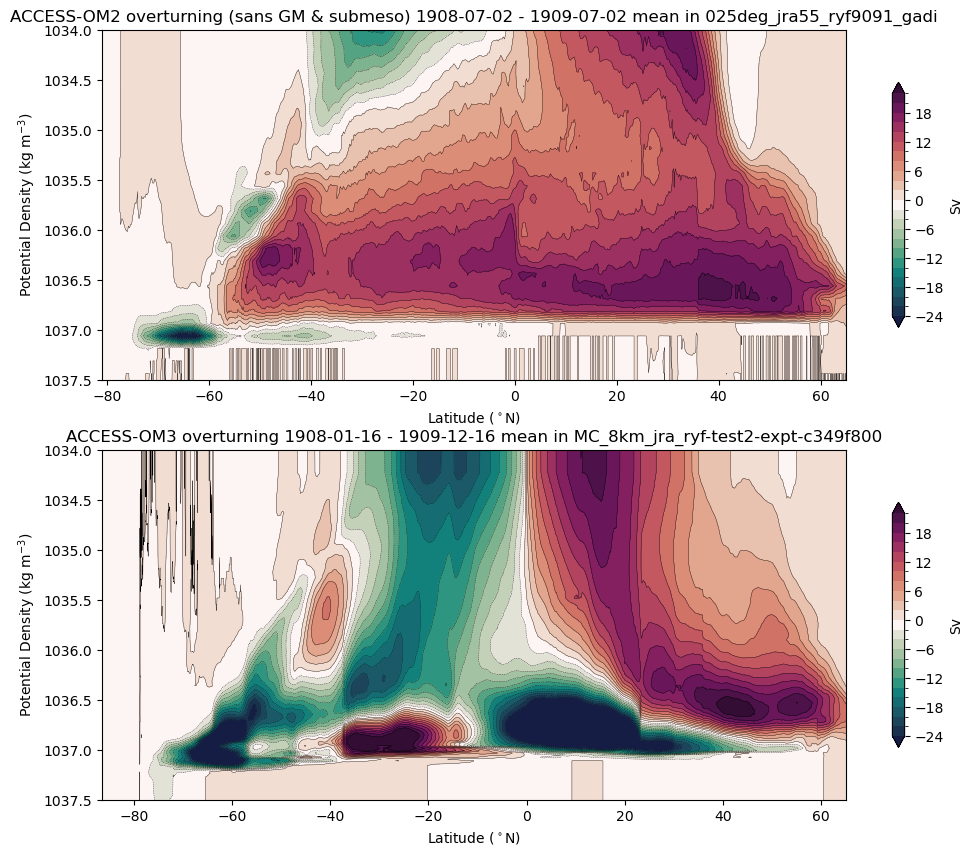

In [26]:
plt.figure(figsize=(12, 10))
levels = range(-24, 24, 2)
plt.subplot(211)
psi_OM2.plot.contourf(
    levels=levels, cmap=cm.cm.curl, extend="both",
    cbar_kwargs={"label": "Sv", "shrink": 0.7}
)
psi_OM2.plot.contour(levels=levels, colors="k", linewidths=0.25)
plt.gca().invert_yaxis()
plt.ylim((1037.5, 1034))
plt.ylabel("Potential Density (kg m$^{-3}$)")
plt.xlabel("Latitude ($^\circ$N)")
if ty_trans_rho_gm_all is not False:
    plt.title(f"{data_name} overturning (sans submeso) {OM2timestr} mean in {om2exptname}")
else:
    plt.title(f"{data_name} overturning (sans GM & submeso) {OM2timestr} mean in {om2exptname}")

plt.subplot(212)
psi_OM3.plot.contourf(
    levels=levels, cmap=cm.cm.curl, extend="both",
    cbar_kwargs={"label": "Sv", "shrink": 0.7}
)
psi_OM3.plot.contour(levels=levels, colors="k", linewidths=0.25)
plt.gca().invert_yaxis()
plt.ylim((1037.5, 1034))
plt.ylabel("Potential Density (kg m$^{-3}$)")
plt.xlabel("Latitude ($^\circ$N)")
plt.title(f"{model_name} overturning {OM3timestr} mean in {exptname}")
mkmd.savefig(plt.gcf(), "Overturning Circulation", "Density-space overturning streamfunction comparing ACCESS-OM3 and ACCESS-OM2. [GitHub issue: Overturning circulation](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/6)")

## Timeseries of overturning at key latitudes

In [27]:
%%time
psi_30S_OM3 = (
    psi_OM3_all.sel(yq=-30, method="nearest")
    .sel(rho2_l=slice(1035, 1038))
    .max(dim="rho2_l")
    .resample(time = '1YE').mean('time')
    .load()
)
psi_26N_OM3 = ( # North Atlantic only, for comparison with RAPID
    psi_OM3_NA.sel(yq=26, method="nearest")
    .sel(rho2_l=slice(1035, 1038))
    .max(dim="rho2_l")
    .resample(time = '1YE').mean('time')
    .load()
)
psi_55N_OM3 = ( # North Atlantic only
    psi_OM3_NA.sel(yq=55, method="nearest")
    .sel(rho2_l=slice(1035, 1038))
    .max(dim="rho2_l")
    .resample(time = '1YE').mean('time')
    .load()
)
psi_abyss_OM3 = (
    -psi_OM3_all.sel(yq=-40, method="nearest")
    .sel(rho2_l=slice(1035, 1038))
    .min(dim="rho2_l")
    .resample(time = '1YE').mean('time')
    .load()
)

CPU times: user 7min 36s, sys: 55 s, total: 8min 31s
Wall time: 11min 39s


In [28]:
%%time
psi_30S_OM2 = (
    psi_OM2_all
    .sel(grid_yu_ocean=-30, method="nearest")
    .sel(potrho=slice(1035, 1038))
    .max(dim="potrho")
    .resample(time = '1YE').mean('time')
    .load()
)
psi_26N_OM2 = ( # North Atlantic only, for comparison with RAPID
    psi_OM2_NA
    .sel(grid_yu_ocean=26, method="nearest")
    .sel(potrho=slice(1035, 1038))
    .max(dim="potrho")
    .resample(time = '1YE').mean('time')
    .load()
)
psi_55N_OM2 = ( # North Atlantic only
    psi_OM2_NA
    .sel(grid_yu_ocean=55, method="nearest")
    .sel(potrho=slice(1035, 1038))
    .max(dim="potrho")
    .resample(time = '1YE').mean('time')
    .load()
)
psi_abyss_OM2 = (
    -psi_OM2_all
    .sel(grid_yu_ocean=-40, method="nearest")
    .sel(potrho=slice(1035, 1038))
    .min(dim="potrho")
    .resample(time = '1YE').mean('time')
    .load()
)

CPU times: user 13.4 s, sys: 703 ms, total: 14.1 s
Wall time: 14.8 s


Saved /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/Overturning_in_ACCESS_OM3_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/Overturning_in_ACCESS_OM3.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/fix-notebooks-ryf-8km-take2/wt/test-ca41efd/notebooks/mkfigs_output_MC_8km_jra_ryf-test2-expt-c349f800/mkmd/Overturning_in_ACCESS_OM3.md successfully.


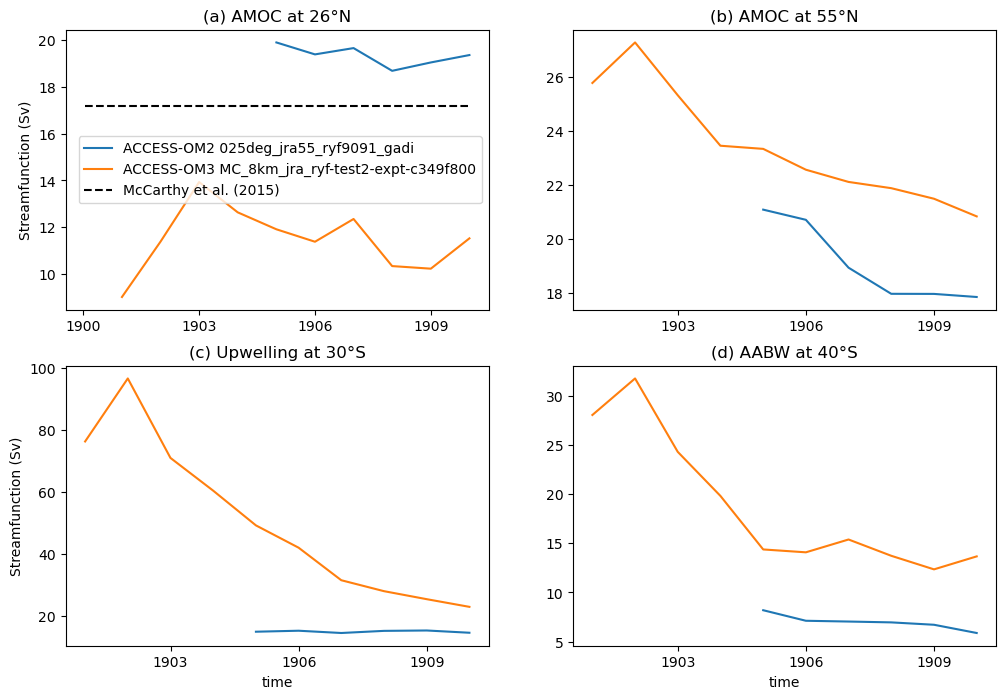

In [29]:
plt.figure(figsize=(12, 8)) 

plt.subplot(221)
psi_26N_OM2.plot(label=f"{data_name} {om2exptname}")
psi_26N_OM3.plot(label=f"{model_name} {exptname}")
# McCarthy, G., Smeed, D., Johns, W., Frajka-Williams, E., Moat, B., Rayner, D., Baringer, M., Meinen, C., Collins, J., and Bryden, H. (2015). Measuring the Atlantic Meridional Overturning Circulation at 26◦N. Progress in Oceanography, 130:91–111.
# http://dx.doi.org/10.1016/j.pocean.2014.10.006
plt.plot([psi_OM3_all.time.values[0], psi_OM3_all.time.values[-1]], [17.2, 17.2],
           'k--', label="McCarthy et al. (2015)")
plt.title('(a) AMOC at 26°N')
plt.ylabel('Streamfunction (Sv)')
plt.legend()
plt.xlabel('')

plt.subplot(222)
psi_55N_OM2.plot()
psi_55N_OM3.plot()
plt.title('(b) AMOC at 55°N')
plt.ylabel('')
plt.xlabel('')

plt.subplot(223)
psi_30S_OM2.plot()
psi_30S_OM3.plot()
plt.title('(c) Upwelling at 30°S')
plt.ylabel('Streamfunction (Sv)')

plt.subplot(224)
psi_abyss_OM2.plot()
psi_abyss_OM3.plot()
plt.title('(d) AABW at 40°S')
plt.ylabel('')
mkmd.savefig(plt.gcf(), "Overturning Circulation", "Timeseries of overturning streamfunction at key latitudes comparing ACCESS-OM3 and ACCESS-OM2. [GitHub issue: AMOC time series](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/7)")